# LSTM Model Iteration

## Importing required libraries

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import kagglehub
from datasets import load_dataset
from sklearn.preprocessing import LabelEncoder
from tensorflow import keras
import tensorflow as tf
import tensorflow_addons as tfa
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Input, Concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, f1_score
import re
import unicodedata
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from imblearn.over_sampling import RandomOverSampler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\tensorflow_addons\utils\tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(
c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\tensorflow_addons\utils\ensure_tf_install.py:53: UserWarning: Tensorflow Addons supports using Python ops for all Tensorflow versions above or equal to 2.12.0 and strictly below 2.15.0 (nightly versions are not supported). 
 The versions of TensorFlow you are currently using is 2.15.0 and is not supported. 
Some things might work, some things might not.
If you were to encounter a bug, do not file an issue.
If 

## Importing Training dataset

In [44]:
# Download latest version (Only once)
# path = kagglehub.dataset_download("zaber666/meld-dataset")

# print("Path to dataset files:", path)

df_meld = pd.read_csv("train_sent_emo.csv") # Adjust based on the directory in which the dataset is located
df_meld.head()

,Sr No.,Utterance,Speaker,Emotion,Sentiment,Dialogue_ID,Utterance_ID,Season,Episode,StartTime,EndTime
0,1,also I was the point person on my companys tr...,Chandler,neutral,neutral,0,0,8,21,"00:16:16,059","00:16:21,731"
1,2,You mustve had your hands full.,The Interviewer,neutral,neutral,0,1,8,21,"00:16:21,940","00:16:23,442"
2,3,That I did. That I did.,Chandler,neutral,neutral,0,2,8,21,"00:16:23,442","00:16:26,389"
3,4,So lets talk a little bit about your duties.,The Interviewer,neutral,neutral,0,3,8,21,"00:16:26,820","00:16:29,572"
4,5,My duties? All right.,Chandler,surprise,positive,0,4,8,21,"00:16:34,452","00:16:40,917"


In [45]:
# Remap meld joy emotion to happiness, fix column names, and drop all unnecassary columns
df_meld = df_meld.rename(columns={"Utterance": "sentence", "Emotion": "emotion"})
df_meld["emotion"] =  df_meld["emotion"].replace({"joy": "happiness"})
df_meld = df_meld[["sentence", "emotion"]]
print(df_meld.columns)
print(df_meld["emotion"].value_counts())


Index(['sentence', 'emotion'], dtype='object')
emotion
neutral      4710
happiness    1743
surprise     1205
anger        1109
sadness       683
disgust       271
fear          268
Name: count, dtype: int64


In [46]:
# Load GoEmotions (train/validation/test splits included)
goemo = load_dataset("go_emotions")
print(goemo)

label_names = goemo["train"].features["labels"].feature.names 
print(label_names)

AttributeError: module 'spacy' has no attribute 'Language'

## Remapping GoEmotions dataset to 6 core + neutral

In [ ]:
# Mapping teh 27 emotions to 6 core + neutral

label_map_ekman = {
    "admiration": "neutral",
    "amusement": "happiness",
    "anger": "anger",
    "annoyance": "anger",
    "approval": "neutral",
    "caring": "happiness",
    "confusion": "surprise",
    "curiosity": "surprise",
    "desire": "happiness",
    "disappointment": "sadness",
    "disapproval": "disgust",
    "disgust": "disgust",
    "embarrassment": "sadness",
    "excitement": "happiness",
    "fear": "fear",
    "gratitude": "happiness",
    "grief": "sadness",
    "joy": "happiness",
    "love": "happiness",
    "nervousness": "fear",
    "optimism": "happiness",
    "pride": "happiness",
    "realization": "surprise",
    "relief": "happiness",
    "remorse": "sadness",
    "sadness": "sadness",
    "surprise": "surprise",
    "neutral": "neutral"
}


The GoEmotions dataset is multi-lable to work around this we decided to pick the first labe as the single label for the emotion

In [ ]:
# Incase sentence have two labels pick the first label as its emotion

def map_labels(example):
    mapped = [label_map_ekman[label_names[i]] for i in example["labels"]]
    if len(mapped) == 0:
        return {"emotion": "neutral"}
    return {"emotion": mapped[0]}  # pick first

goemo_mapped = goemo.map(map_labels)


In [ ]:
df_goemo = pd.DataFrame({
    "sentence": goemo_mapped["train"]["text"],
    "emotion": goemo_mapped["train"]["emotion"]
})

print(df_goemo.head())
print(df_goemo["emotion"].value_counts())


                                            sentence  emotion
0  My favourite food is anything I didn't have to...  neutral
1  Now if he does off himself, everyone will thin...  neutral
2                     WHY THE FUCK IS BAYLESS ISOING    anger
3                        To make her feel threatened     fear
4                             Dirty Southern Wankers    anger
emotion
neutral      19549
happiness    10222
surprise      4489
anger         3685
sadness       2619
disgust       2231
fear           615
Name: count, dtype: int64


In [ ]:
df_last_year = pd.read_excel("combined_last_year_useful.xlsx")
df_last_year = df_last_year.rename(columns={"emotion_core": "emotion", "Translation": "sentence", "Sentence": "original", "Emotion": "advanced"})
df_last_year = df_last_year[["sentence", "emotion"]]
df_last_year = df_last_year.dropna()
df_last_year.head()

,sentence,emotion
1,Start the timer,neutral
2,What are we gonna do like do we just stand here,neutral
3,Every 60 seconds someone gets eliminated. The ...,neutral
4,Let's see if they figure it out. So it's to vo...,happiness
5,What do you guys want to vote for? Is it vote ...,neutral


In [ ]:
df_student = pd.read_excel("combined_peer_reviewed_dataset.xlsx")

df_student = df_student.rename(columns={"Corrected_emotion": "emotion", "Translation": "sentence", "Sentence": "original"})
df_student = df_student[["sentence", "emotion"]]
df_student.head()

,sentence,emotion
0,I would most like to continue with Martijn and...,neutral
1,I now have the distinct impression that I have...,sadness
2,Jan reaches his emotional breaking point.,sadness
3,And South goes wild for a moment.,happiness
4,Here I found my baby.,happiness


## Combining both datasets to 1 dataframe to use for training models

In [ ]:
df_combined = pd.concat([df_meld[["sentence","emotion"]], df_goemo[["sentence","emotion"]], df_student[["sentence", "emotion"]], df_last_year[["sentence", "emotion"]]], ignore_index=True)
print(df_combined.shape)
print(df_combined["emotion"].value_counts())

# df_combined.to_csv("combined_dataset_full.csv")




(68253, 2)
emotion
neutral      31043
happiness    16646
surprise      6416
anger         5637
sadness       4054
disgust       3047
fear          1410
Name: count, dtype: int64


In [3]:
df_combined = pd.read_excel("nnnhis_year_and_last_year_cleanedmix_shuffled1.xlsx")
df_combined["sentence"] = df_combined["sentence"].fillna("").astype(str)
df_combined.head()

,sentence,emotion
0,I feel horrible.,sadness
1,He wants to couple with her.,happiness
2,"basketball, his life revolved around their liv...",happiness
3,I've made a decision to strengthen the team.,neutral
4,My throat’s dry.,fear


## Iteration 1: Baseline

### Encode labels and split into train and validation splits (We do not split into test splits since we are going to be using our own data for the test split)

In [4]:
# Encode emotions
label_encoder = LabelEncoder()
df_combined["label"] = label_encoder.fit_transform(df_combined["emotion"])

X = df_combined["sentence"].values
y = df_combined["label"].values

# split into train validation split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size = 0.1, random_state=42, stratify=y
)

In [52]:
# Replace NaN rows with empty space and change the datatype to strings 
X_train = pd.Series(X_train).fillna("").astype(str).tolist()
X_val   = pd.Series(X_val).fillna("").astype(str).tolist()

# Sanity check to make sure all rows are strings
bad_idx = [i for i,x in enumerate(X_train) if not isinstance(x, str)]
print("Non-strings in X_train at indices:", bad_idx[:10])

Non-strings in X_train at indices: []


### Tokenizing words into vectors an padding those vectors so they can used in a LSTM model since LSTM models require the input to be the same size 

In [5]:
max_words = 20000 # keep the 20000 most common words in the corpus so the model doesnt waste time training sentences that only happen onces
max_len = 100 # Fix input length for padding the vectors

# Build vocabulary from trainig data
tokenzier = Tokenizer(num_words=max_words, oov_token="<OOV>") # replace words out of the corpus with OOV
tokenzier.fit_on_texts(X_train)

# Convert sentences into integer sequences 
X_train_seq = tokenzier.texts_to_sequences(X_train)
X_val_seq = tokenzier.texts_to_sequences(X_val)

# pad to fix length issues
X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding="post", truncating="post")
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len, padding="post", truncating="post")


### Train LSTM model

In [6]:
embedding_dim = 128

model = Sequential([
    Embedding(input_dim = max_words, output_dim = embedding_dim, input_length = max_len),
    LSTM(128, return_sequences = False),
    Dropout(0.5),
    Dense(64, activation = "relu"),
    Dropout(0.3),
    Dense(len(label_encoder.classes_), activation = "softmax")
])

model.compile(loss = "sparse_categorical_crossentropy",
              optimizer = "adam",
              metrics = ["accuracy"])

model.summary()



Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 100, 128)          2560000   
                                                                 
 lstm (LSTM)                 (None, 128)               131584    
                                                                 
 dropout (Dropout)           (None, 128)               0         
                                                                 
 dense (Dense)               (None, 64)                8256      
                                                                 
 dropout_1 (Dropout)         (None, 64)                0         
                                                                 
 dense_1 (Dense)             (None, 7)                 455       
                                                                 
Total params: 2700295 (10.30 MB)
Trainable params: 270

In [7]:
history = model.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=3,        # keep small for baseline
    batch_size=32,
    verbose=1
)


Epoch 1/3


826/826 [==============================] - 32s 37ms/step - loss: 1.7550 - accuracy: 0.3445 - val_loss: 1.7385 - val_accuracy: 0.3484
Epoch 2/3
826/826 [==============================] - 31s 37ms/step - loss: 1.7437 - accuracy: 0.3484 - val_loss: 1.7387 - val_accuracy: 0.3484
Epoch 3/3
826/826 [==============================] - 33s 40ms/step - loss: 1.7418 - accuracy: 0.3485 - val_loss: 1.7381 - val_accuracy: 0.3484


### Evaluating The model

In [8]:
# Loading and pre process test dataset
df_test = pd.read_csv("group_23_url_1_transcript.csv")
# Keep only the necessary columns
df_test = df_test[["Sentence", "Emotion_core"]]
df_test.head()

,Sentence,Emotion_core
0,"Previously on Australian Survivor, Tara and Lo...",happiness
1,I'm trusting you with this because I'm sitting...,fear
2,But Tara decided it was time for a breakup.,sadness
3,"It breaks my heart, but he's got to go.",sadness
4,It wasn't the only moral dilemma Tara faced.,neutral


In [9]:
# Encode labels with the same encoder used in training
df_test["label"] = label_encoder.transform(df_test["Emotion_core"])

X_test = df_test["Sentence"].values
y_test = df_test["label"].values

# Tokenize and pad with the same tokenizer
X_test_seq = tokenzier.texts_to_sequences(X_test)
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding="post", truncating="post")

# Get predictions
y_test_pred = model.predict(X_test_pad)
y_test_pred_classes = y_test_pred.argmax(axis = 1)

# Compute macro F1 
macro_f1 = f1_score(y_test, y_test_pred_classes, average="macro")
print("Macro F1 score on Test Data:", macro_f1)

# Detailed per class evaluation report
print(classification_report(y_test, y_test_pred_classes, target_names=label_encoder.classes_))

21/21 [==============================] - 0s 11ms/step
Macro F1 score on Test Data: 0.06832298136645963
              precision    recall  f1-score   support

       anger       0.00      0.00      0.00        54
     disgust       0.00      0.00      0.00         6
        fear       0.00      0.00      0.00       101
   happiness       0.00      0.00      0.00       156
     neutral       0.31      1.00      0.48       209
     sadness       0.00      0.00      0.00        88
    surprise       0.00      0.00      0.00        51

    accuracy                           0.31       665
   macro avg       0.04      0.14      0.07       665
weighted avg       0.10      0.31      0.15       665



c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [12]:
from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(y_test, y_test_pred_classes, output_dict=True)
df_report = pd.DataFrame(report).transpose()

# Drop the summary rows (accuracy, macro avg, weighted avg)
df_report = df_report.iloc[:-3]

# Convert precision/recall/f1 into %
df_report["precision"] = df_report["precision"] * 100
df_report["recall"]    = df_report["recall"] * 100
df_report["f1-score"]  = df_report["f1-score"] * 100

print(df_report[["precision", "recall", "f1-score"]].round(2))


   precision  recall  f1-score
0       0.00     0.0      0.00
1       0.00     0.0      0.00
2       0.00     0.0      0.00
3       0.00     0.0      0.00
4      31.43   100.0     47.83
5       0.00     0.0      0.00
6       0.00     0.0      0.00


c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [14]:
df_report.head()


,precision,recall,f1-score,support
0,0.000000,0.0,0.000000,54.0
1,0.000000,0.0,0.000000,6.0
2,0.000000,0.0,0.000000,101.0
3,0.000000,0.0,0.000000,156.0
4,31.428571,100.0,47.826087,209.0


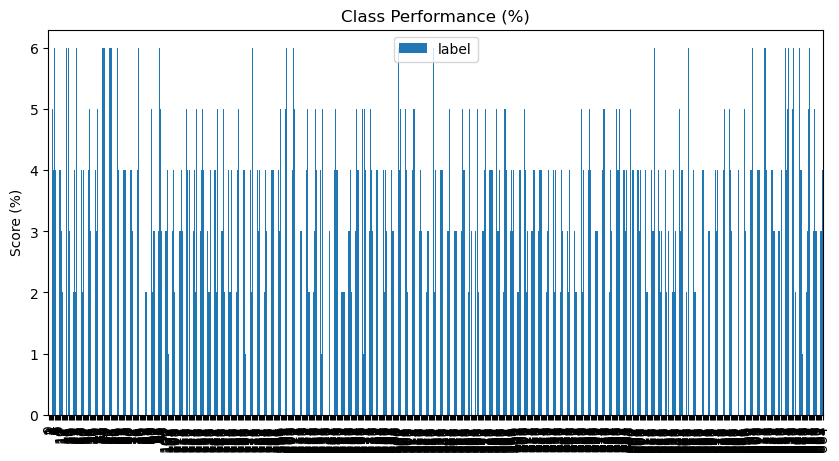

In [13]:
df_test.plot(kind="bar", figsize=(10,5), title="Class Performance (%)")
plt.ylabel("Score (%)")
plt.show()


21/21 [==============================] - 0s 12ms/step


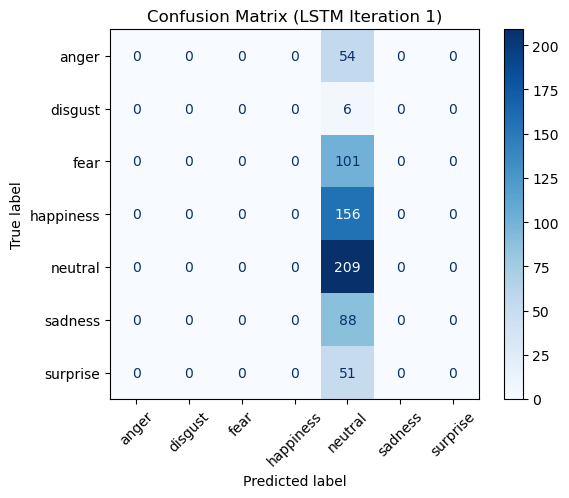

In [10]:
# Get predictions (example for iteration 3 model)
y_test_pred = model.predict(X_test_pad).argmax(axis=1)

# Compute confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
plt.title("Confusion Matrix (LSTM Iteration 1)")
plt.show()

In [11]:
# Predict on validation set
y_val_pred = model.predict(X_val_pad)
y_val_pred_classes = y_val_pred.argmax(axis=1)

# Compute Macro F1
macro_f1_val = f1_score(y_val, y_val_pred_classes, average="macro")
print("Macro F1 Score on Validation Data:", macro_f1_val)

# Full classification report
print(classification_report(y_val, y_val_pred_classes, target_names=label_encoder.classes_))

92/92 [==============================] - 1s 11ms/step
Macro F1 Score on Validation Data: 0.0738281672861112
              precision    recall  f1-score   support

       anger       0.00      0.00      0.00       279
     disgust       0.00      0.00      0.00       226
        fear       0.00      0.00      0.00       272
   happiness       0.00      0.00      0.00       698
     neutral       0.35      1.00      0.52      1023
     sadness       0.00      0.00      0.00       240
    surprise       0.00      0.00      0.00       198

    accuracy                           0.35      2936
   macro avg       0.05      0.14      0.07      2936
weighted avg       0.12      0.35      0.18      2936



c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Takeaways from baseline model

The model classifies everything to the neutral class, in both the validation and the test set, this is likely due to the heavy class imbalance of the data, meaning for the future iterations we would have to balance the classes to make sure the model doesnt collapse and classify everything as netural 

# Iteration 2: pre-processing + Sentiment score

In [60]:
# Pre-processing texts

def preprocess_text(text):
    # handling missing values
    if pd.isna(text):
        return ""
    text = str(text)
    text = text.lower()

    #Normalize weird unicode (removing things like Ä, non-breaking spaces)
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("utf-8", "ignore")

    # Keep letters and punctuation (! ? . , …) but drop numbers/symbols
    text = re.sub(r"[^a-zA-Z!?.,'\s]", " ", text)

    # Removing usernames / mentions
    text = re.sub(r"@\w", " ", text)

    # Removing things like [NAME] or [something]
    text = re.sub(r"\[.*?\]", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


In [61]:
df_combined = df_combined.dropna(subset=["sentence"])
df_combined = df_combined.drop_duplicates(subset=["sentence"])
df_combined["clean_sentence"] = df_combined["sentence"].apply(preprocess_text)

### Sentiment Analysis using vader

In [62]:
# Sentiment Analysis
nltk.download("vader_lexicon")
sid = SentimentIntensityAnalyzer()

def get_sentiment_scores(text):
    scores = sid.polarity_scores(str(text))
    return [scores["neg"], scores["neu"], scores["pos"], scores["compound"]] # The different scores we want to get

sentiment_features = df_combined["clean_sentence"].apply(get_sentiment_scores)
sentiment_features = np.array(sentiment_features.tolist())

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\Barsam/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [63]:
# Tokenize and pad the input

X_seq = tokenzier.texts_to_sequences(df_combined["clean_sentence"].values)
X_pad = pad_sequences(X_seq, maxlen=max_len, padding = "post", truncating="post")

# Split into training and validation sets for both the input and the sentiment scores 
X_train_pad, X_val_pad, sent_train, sent_val, y_train, y_val = train_test_split(
    X_pad, sentiment_features, df_combined["label"].values, test_size = 0.1,
    random_state=42, stratify=df_combined["label"].values
)

In [64]:
# Sequence input
seq_input = Input(shape=(max_len,))
embedding_layer = Embedding(
    input_dim = max_words,
    output_dim = 128,
    input_length = max_len,
    trainable = True
)(seq_input)

# Stacked LSTM layers
lstm = LSTM(128, return_sequences=True)(embedding_layer)
lstm = Dropout(0.5)(lstm)
lstm = LSTM(64)(lstm)
lstm = Dropout(0.3)(lstm)

# Sentiment input
sent_input = Input(shape=(4,))
dense_sent = Dense(16, activation = "relu")(sent_input)

# Merge both
merged = Concatenate()([lstm, dense_sent])
dense_out = Dense(64, activation = "relu")(merged)
dropout = Dropout(0.3)(dense_out)
final_out = Dense(len(label_encoder.classes_), activation = "softmax")(dropout)

# Build model
model_2 = Model(inputs = [seq_input, sent_input], outputs = final_out)

model_2.compile(loss="sparse_categorical_crossentropy",
                optimizer = "adam",
                metrics = ["accuracy"])

model_2.summary()

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_3 (InputLayer)        [(None, 100)]                0         []                            
                                                                                                  
 embedding_3 (Embedding)     (None, 100, 128)             2560000   ['input_3[0][0]']             
                                                                                                  
 lstm_4 (LSTM)               (None, 100, 128)             131584    ['embedding_3[0][0]']         
                                                                                                  
 dropout_7 (Dropout)         (None, 100, 128)             0         ['lstm_4[0][0]']              
                                                                                            

In [65]:
# Flatten out sequence and sentiment features into one array for oversampling
X_train_combined = np.hstack([X_train_pad, sent_train])

ros = RandomOverSampler(random_state=42)
X_resampled, y_resampled = ros.fit_resample(X_train_combined, y_train)

X_train_pad_resampled = X_resampled[:, :X_train_pad.shape[1]]
sent_train_resampled = X_resampled[:, X_train_pad.shape[1]:]

print("Before:", np.bincount(y_train))
print("After:", np.bincount(y_resampled))


Before: [2303 1854 2204 5713 7819 2033 1388]
After: [7819 7819 7819 7819 7819 7819 7819]


c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


In [66]:
early_stop = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

h2 = model_2.fit(
    [X_train_pad_resampled, sent_train_resampled], y_resampled,
    validation_data=([X_val_pad, sent_val], y_val),
    epochs=10,        
    batch_size=32,
    callbacks = [early_stop],
    verbose=1
)


Epoch 1/10
1711/1711 [==============================] - 104s 60ms/step - loss: 1.8509 - accuracy: 0.2330 - val_loss: 1.8102 - val_accuracy: 0.3979
Epoch 2/10
1711/1711 [==============================] - 94s 55ms/step - loss: 1.8315 - accuracy: 0.2480 - val_loss: 1.7636 - val_accuracy: 0.4118
Epoch 3/10
1711/1711 [==============================] - 92s 54ms/step - loss: 1.8273 - accuracy: 0.2528 - val_loss: 1.7797 - val_accuracy: 0.4099
Epoch 4/10
1711/1711 [==============================] - 86s 50ms/step - loss: 1.8238 - accuracy: 0.2555 - val_loss: 1.7573 - val_accuracy: 0.4203
Epoch 5/10
1711/1711 [==============================] - 88s 52ms/step - loss: 1.8224 - accuracy: 0.2561 - val_loss: 1.7900 - val_accuracy: 0.4091
Epoch 6/10
1711/1711 [==============================] - 85s 50ms/step - loss: 1.8217 - accuracy: 0.2574 - val_loss: 1.7735 - val_accuracy: 0.4164


In [67]:
# Generate sentiment features for test sentences
sent_test = df_test["Sentence"].apply(get_sentiment_scores)
sent_test = np.array(sent_test.tolist())

print(sent_test.shape)
print(sent_test[:5])


(665, 4)
[[ 0.      0.839   0.161   0.3612]
 [ 0.      0.828   0.172   0.4019]
 [ 0.      1.      0.      0.    ]
 [ 0.      1.      0.      0.    ]
 [ 0.195   0.805   0.     -0.1779]]


In [68]:
# Get predictions
y_test_pred = model_2.predict([X_test_pad, sent_test])
y_test_pred_classes = y_test_pred.argmax(axis = 1)

# Compute macro F1 
macro_f1 = f1_score(y_test, y_test_pred_classes, average="macro")
print("Macro F1 score on Test Data:", macro_f1)

# Detailed per class evaluation report
print(classification_report(y_test, y_test_pred_classes, target_names=label_encoder.classes_))

21/21 [==============================] - 1s 15ms/step
Macro F1 score on Test Data: 0.20554627065380693
              precision    recall  f1-score   support

       anger       0.50      0.02      0.04        54
     disgust       0.02      0.17      0.03         6
        fear       0.30      0.03      0.05       101
   happiness       0.51      0.65      0.57       156
     neutral       0.47      0.79      0.59       209
     sadness       0.22      0.11      0.15        88
    surprise       0.00      0.00      0.00        51

    accuracy                           0.43       665
   macro avg       0.29      0.25      0.21       665
weighted avg       0.38      0.43      0.35       665



21/21 [==============================] - 0s 17ms/step


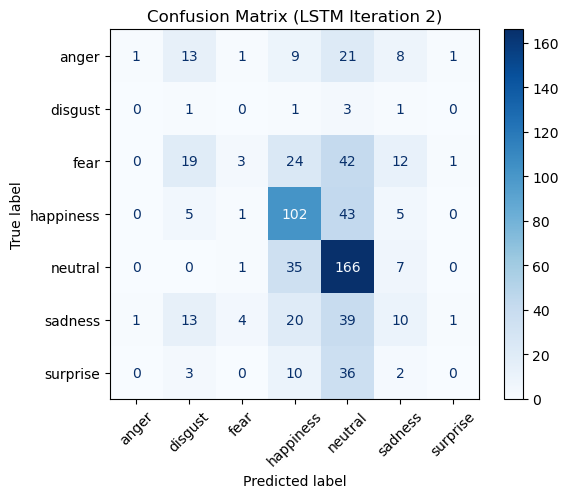

In [69]:
# Get predictions (example for iteration 3 model)
y_test_pred = model_2.predict([X_test_pad, sent_test]).argmax(axis=1)

# Compute confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
plt.title("Confusion Matrix (LSTM Iteration 2)")
plt.show()

In [70]:
# Predict on validation set
y_val_pred = model_2.predict([X_val_pad, sent_val])
y_val_pred_classes = y_val_pred.argmax(axis=1)

# Compute Macro F1
macro_f1_val = f1_score(y_val, y_val_pred_classes, average="macro")
print("Macro F1 Score on Validation Data:", macro_f1_val)

# Full classification report
print(classification_report(y_val, y_val_pred_classes, target_names=label_encoder.classes_))

81/81 [==============================] - 1s 15ms/step
Macro F1 Score on Validation Data: 0.23309119788884056
              precision    recall  f1-score   support

       anger       0.50      0.00      0.01       256
     disgust       0.27      0.50      0.35       206
        fear       0.16      0.02      0.04       245
   happiness       0.53      0.45      0.49       635
     neutral       0.44      0.76      0.56       869
     sadness       0.24      0.16      0.19       226
    surprise       0.00      0.00      0.00       154

    accuracy                           0.42      2591
   macro avg       0.31      0.27      0.23      2591
weighted avg       0.39      0.42      0.36      2591



## Takeaways from iteration 2:

The second iteration shows considerable improvements, the use of sentiment analysis, pre-processing and over sampling fixes the model collapse issue faced in the baseline model, although the overall performance of the model isnt perfect the fact that its no longer collapsing and only predicting one thing for all the features means the model can be improved in the third iteration. For the third iteration the best course of action is to add POS tagging and depending on the output and performance of the model using POS tagging adding TF-IDF could really improve the models performance now that its no longer collapsing.

# Iteration 3: sentiment analysis + POS tagging + TF-IDF

In [71]:
import spacy

nlp = spacy.load("en_core_web_sm")

def get_pos_features(text):
    doc = nlp(text)
    counts = {"ADJ":0, "ADV":0, "NOUN":0, "VERB":0}
    for token in doc:
        if token.pos_ == "ADJ":
            counts["ADJ"] += 1
        elif token.pos_ == "ADV":
            counts["ADV"] += 1
        elif token.pos_ == "NOUN":
            counts["NOUN"] += 1
        elif token.pos_ == "VERB":
            counts["VERB"] += 1
    return list(counts.values())

# Apply to dataset
pos_features = df_combined["clean_sentence"].apply(get_pos_features)
pos_features = np.array(pos_features.tolist())
print(pos_features.shape, pos_features[:5], pos_features.dtype)

(25905, 4) [[1 0 0 1]
 [0 0 0 2]
 [1 1 3 1]
 [0 0 2 2]
 [0 0 1 1]] int32


In [72]:
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1,2))

X_tfidf = tfidf.fit_transform(df_combined["clean_sentence"]).toarray()
print("TF-IDF shape:", X_tfidf.shape)

TF-IDF shape: (25905, 5000)


In [73]:
# Tokenize and pad the input

X_seq = tokenzier.texts_to_sequences(df_combined["sentence"].values)
X_pad = pad_sequences(X_seq, maxlen=max_len, padding = "post", truncating="post")

# Split into training and validation sets for the input, sentiment scores, and the POS tags
X_train_pad, X_val_pad, sent_train, sent_val, pos_train, pos_val, tfidf_train, tfidf_val, y_train, y_val = train_test_split(
    X_pad, sentiment_features,pos_features, X_tfidf, df_combined["label"].values, test_size = 0.1,
    random_state=42, stratify=df_combined["label"].values
)


In [ ]:
## Building the model

seq_input = Input(shape=(max_len,))
embedding_layer = Embedding(
    input_dim = max_words,
    output_dim = 128,
    input_length = max_len,
    trainable = True
)(seq_input)

# Stacked LSTM layers
lstm = LSTM(128, return_sequences=True)(embedding_layer)
lstm = Dropout(0.5)(lstm)
lstm = LSTM(64)(lstm)
lstm = Dropout(0.3)(lstm)

# Sentiment input
sent_input = Input(shape=(4,))
dense_sent = Dense(16, activation = "relu")(sent_input)

# POS input
pos_input = Input(shape=(4,))
dense_pos = Dense(16, activation = "relu")(pos_input)


# TF-IDF branch
tfidf_input = Input(shape=(X_tfidf.shape[1],))
dense_tfidf = Dense(128, activation = "relu")(tfidf_input)
dense_tfidf = Dropout(0.3)(dense_tfidf)

# Merge
merged = Concatenate()([lstm, dense_sent, dense_pos, dense_tfidf])
dense_out = Dense(64, activation = "relu")(merged)
dropout = Dropout(0.3)(dense_out)
final_out = Dense(len(label_encoder.classes_), activation = "softmax")(dropout)

#Build model
model_3 = Model(inputs=[seq_input, pos_input, sent_input, tfidf_input], outputs = final_out)
model_3.compile(loss = "sparse_categorical_crossentropy",
                optimizer = "adam", 
                metrics = ["accuracy"])

model_3.summary()

Model: "model_2"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_5 (InputLayer)        [(None, 100)]                0         []                            
                                                                                                  
 embedding_3 (Embedding)     (None, 100, 128)             2560000   ['input_5[0][0]']             
                                                                                                  
 lstm_5 (LSTM)               (None, 100, 128)             131584    ['embedding_3[0][0]']         
                                                                                                  
 dropout_8 (Dropout)         (None, 100, 128)             0         ['lstm_5[0][0]']              
                                                                                            

In [74]:
# Stack sentiment, POS, TF-IDF for resampling together
extra_train = np.hstack([sent_train, pos_train, tfidf_train])

# Oversample
ros = RandomOverSampler(random_state=42)
extra_resampled, y_train_resampled = ros.fit_resample(extra_train, y_train)

# Get indices of rows that were resampled
indices = ros.sample_indices_

# Apply same resampling to padded sequences
X_train_pad_resampled = X_train_pad[indices]

# Now split extra_resampled back into features
sent_train_resampled = extra_resampled[:, :sent_train.shape[1]]
pos_train_resampled  = extra_resampled[:, sent_train.shape[1]:sent_train.shape[1]+pos_train.shape[1]]
tfidf_train_resampled = extra_resampled[:, sent_train.shape[1]+pos_train.shape[1]:]

c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
c:\Users\Barsam\miniconda3\envs\Y2bA\lib\site-packages\sklearn\base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


In [75]:
# Sanity check for making sure the validation splits are correct

print([arr.shape for arr in [X_val_pad, sent_val, pos_val, tfidf_val]])
print(y_val.shape)
print(type(X_val_pad), type(sent_val), type(pos_val), type(tfidf_val))



[(2591, 100), (2591, 4), (2591, 4), (2591, 5000)]
(2591,)
<class 'numpy.ndarray'> <class 'numpy.ndarray'> <class 'numpy.ndarray'> <class 'numpy.ndarray'>


In [76]:
X_val_pad = np.array(X_val_pad, dtype=np.int32)
sent_val  = np.array(sent_val, dtype=np.float32)
pos_val   = np.array(pos_val, dtype=np.float32)
y_val     = np.array(y_val, dtype=np.int32)
tfidf_val = np.array(tfidf_val, dtype=np.float32)

In [ ]:
h3 = model_3.fit(
    [X_train_pad_resampled, sent_train_resampled, pos_train_resampled, tfidf_train_resampled], y_resampled,
    validation_data=([X_val_pad, sent_val, pos_val, tfidf_val], y_val),
    epochs=10,        
    batch_size=32,
    callbacks = [early_stop],
    verbose=1
)

Epoch 1/10
1711/1711 [==============================] - 95s 56ms/step - loss: 0.9486 - accuracy: 0.6647 - val_loss: 1.3125 - val_accuracy: 0.5203
Epoch 2/10
1711/1711 [==============================] - 86s 50ms/step - loss: 0.5822 - accuracy: 0.7965 - val_loss: 1.4671 - val_accuracy: 0.5399
Epoch 3/10
1711/1711 [==============================] - 87s 51ms/step - loss: 0.4139 - accuracy: 0.8535 - val_loss: 1.6319 - val_accuracy: 0.5535


In [ ]:
pos_test= df_test["Sentence"].apply(get_pos_features)
pos_test = np.array(pos_test.tolist())

print(pos_test.shape)
print(pos_test[:5])

(665, 4)
[[1 1 2 0]
 [0 0 2 2]
 [0 0 2 1]
 [0 0 1 3]
 [2 0 1 1]]


In [ ]:
tfidf_test  = tfidf.transform(X_test).toarray()
print("TF-IDF shape:", tfidf_test.shape)

TF-IDF shape: (665, 5000)


21/21 [==============================] - 0s 17ms/step


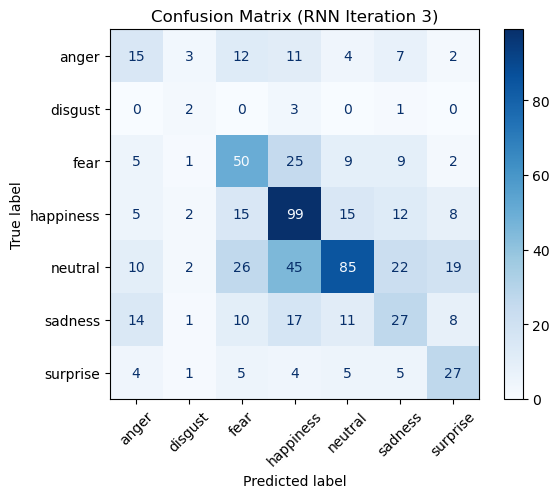

In [ ]:
# Get predictions (example for iteration 3 model)
y_test_pred = model_3.predict([X_test_pad, sent_test, pos_test, tfidf_test]).argmax(axis=1)

# Compute confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
plt.title("Confusion Matrix (LSTM Iteration 3)")
plt.show()

In [ ]:
# Predict on validation set
y_val_pred = model_3.predict([X_val_pad, sent_val, pos_val, tfidf_val])
y_val_pred_classes = y_val_pred.argmax(axis=1)

# Compute Macro F1
macro_f1_val = f1_score(y_val, y_val_pred_classes, average="macro")
print("Macro F1 Score on Validation Data:", macro_f1_val)

# Full classification report
print(classification_report(y_val, y_val_pred_classes, target_names=label_encoder.classes_))

81/81 [==============================] - 2s 16ms/step
Macro F1 Score on Validation Data: 0.504079212492422
              precision    recall  f1-score   support

       anger       0.43      0.50      0.46       256
     disgust       0.52      0.61      0.56       206
        fear       0.54      0.60      0.57       245
   happiness       0.57      0.55      0.56       635
     neutral       0.63      0.47      0.54       869
     sadness       0.38      0.53      0.45       226
    surprise       0.34      0.47      0.39       154

    accuracy                           0.52      2591
   macro avg       0.49      0.53      0.50      2591
weighted avg       0.54      0.52      0.52      2591

